# 3D Bin Packing Problem  AI Search & Optimisation

---


## Comparative Study: Greedy · Simulated Annealing · Genetic Algorithm

**Course:** Introduction to Artificial Intelligence  
**School:** ENSIA
**Academic Year:** 2025-2026

---

> This notebook implements and compares three approaches to the **3D Bin Packing Problem (3DBPP)**:  
> a greedy heuristic baseline, Simulated Annealing (SA), and a Genetic Algorithm (GA).  
> All algorithms share the same physical model, constraint checker, and objective function,  
> enabling a fair apples-to-apples comparison.


In [ ]:
!pip install matplotlib plotly numpy pandas

## Table of Contents
1. [Problem Description](#1)
2. [Dataset Description](#2)
3. [Dependencies & Setup](#3)
4. [Shared Data Model: Box & Container](#4)
5. [Shared Utilities: Constraints, Objective, Visualisation](#5)
6. [Algorithm 1 — Greedy Heuristic](#6)
7. [Algorithm 2 — Simulated Annealing](#7)
8. [Algorithm 3 — Genetic Algorithm](#8)
9. [Results & Comparative Analysis](#9)
10. [Conclusion](#10)


---
<a id='1'></a>
## 1. Problem Description

The **3D Bin Packing Problem (3DBPP)** is an NP-hard combinatorial optimisation problem.  
Given a set of rectangular boxes with known dimensions and a single container (truck cargo space),  
the goal is to pack as many boxes as possible while satisfying the following real-world constraints:

| Constraint | Description |
|---|---|
| **Boundary** | Every box must fit entirely within the container walls |
| **No overlap** | Boxes may not intersect |
| **Gravity / support** | At least **70%** of a box's base area must rest on the floor or on another box |
| **Fragility** | Fragile boxes cannot have any box placed on top of them; they are also orientation-restricted |
| **Rotation** | Each box may be placed in up to **6 orientations** (reduced to 2 for fragile boxes) |

The problem is modelled as a **state-space search** where each state is a complete packing  
assignment (ordering + orientation of boxes). Three search strategies are compared:

- **Greedy** — deterministic, single-pass, used as a baseline.
- **Simulated Annealing (SA)** — stochastic local search that escapes local optima through controlled random perturbations.
- **Genetic Algorithm (GA)** — population-based evolutionary search combining selection, crossover, mutation and elitism.


---
<a id='2'></a>
## 2. Dataset Description

### 2.1 Data Source & Collection

To ensure realistic box and truck characteristics, the team visited several Algerian delivery  
companies including **Yalidine**, **ZR Express**, and **Anderson** across multiple cities.  
Some companies shared catalogues of frequently used package sizes, while others noted  
that customers may ship items with arbitrary dimensions depending on the product  
(common household, school, or commercial objects). Several services confirmed that  
dimensions are entered into their systems for operational purposes and are **not**  
maintained as structured historical datasets.

Consequently, part of the dataset was generated using the real dimension ranges and  
box catalogues provided by the visited companies — particularly Anderson.  
The collected information was unified into a **single dataset of 109 boxes**  
representing realistic Algerian domestic delivery scenarios.

### 2.2 Generation Parameters

Box dimensions were sampled **uniformly at random** within the following ranges:

| Attribute | Distribution | Min | Max |
|---|---|---|---|
| Length | U[8, 70] cm | 8 | 70 |
| Width | U[6, 45] cm | 6 | 45 |
| Height | U[3, 45] cm | 3 | 45 |
| Weight | U[0.05, 9] kg | 0.05 | 9 |
| Fragile flag | ~30% probability | 0 | 1 |

**Truck (container) dimensions:** 160 × 105 × 80 cm  → total volume **1,344,000 cm³**

### 2.3 Dataset Characteristics

| Attribute | Min | Max | Mean | Std Dev |
|---|---|---|---|---|
| Length (cm) | 8 | 70 | 28.25 | 11.11 |
| Width (cm) | 6 | 45 | 21.34 | 8.62 |
| Height (cm) | 3 | 45 | 10.71 | 8.00 |
| Weight (kg) | 0.05 | 9 | 0.87 | 1.11 |
| Volume (cm³) | 180 | 141,750 | 10,182 | 19,932 |
| Fragile boxes | — | — | ~22.9% | — |

*Table 1: Summary statistics of the 109-box synthetic dataset.*

> **Note:** The dataset file (`dataset.csv`) is located in the `Data/` folder alongside this notebook.  
> Place the `Data/` folder in the **same directory** as this notebook before running.


In [28]:
# ── Dataset quick-look ───────────────────────────────────────────────────────
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# Load and inspect the dataset
DATA_PATH = r"Data\dataset.csv"
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()

print(f"Dataset shape: {df.shape[0]} boxes × {df.shape[1]} attributes")
print()
df.head(10)


Dataset shape: 109 boxes × 9 attributes



,ID,Name,Source,Length_cm,Width_cm,Height_cm,Weight_kg,volume_cm3,fragile_flag
0,1,nails,Mars Express Sidi bel abbes,20.0,13.0,8.0,0.3,2080.0,0
1,2,small notebook,Mars Express Sidi bel abbes,20.0,18.0,8.0,0.3,2880.0,0
2,3,kitchen containers,Mars Express Sidi bel abbes,20.0,20.0,10.0,0.5,4000.0,1
3,4,phone screen protector,Mars Express Sidi bel abbes,21.0,16.0,3.0,0.1,1008.0,0
4,5,deodorant,Mars Express Sidi bel abbes,23.0,9.0,8.0,0.2,1656.0,0
5,6,beauty products,Mars Express Sidi bel abbes,25.0,18.0,8.0,0.4,3600.0,1
6,7,posters,Mars Express Sidi bel abbes,25.0,25.0,8.0,0.2,5000.0,0
7,8,shirt,Mars Express Sidi bel abbes,31.0,21.0,5.0,0.3,3255.0,0
8,9,hoodie,Mars Express Sidi bel abbes,35.0,25.0,7.0,0.7,6125.0,0
9,10,towels,Mars Express Sidi bel abbes,25.0,12.0,6.0,0.4,1800.0,0


In [29]:
# ── Summary statistics ───────────────────────────────────────────────────────
print("=== Summary Statistics ===")
print(df[['Length_cm','Width_cm','Height_cm','Weight_kg']].describe().round(4))
print()
print(f"Fragile boxes : {df['fragile_flag'].sum()}  ({df['fragile_flag'].mean()*100:.1f}%)")
print(f"Normal  boxes : {(df['fragile_flag']==0).sum()}")


=== Summary Statistics ===
       Length_cm  Width_cm  Height_cm  Weight_kg
count   109.0000  109.0000   109.0000   109.0000
mean     28.2505   21.3422    10.7092     0.8748
std      11.1124    8.6245     7.9993     1.1150
min       8.0000    6.0000     3.0000     0.0500
25%      20.0000   15.0000     7.0000     0.4000
50%      30.0000   20.0000     8.0000     0.6000
75%      35.0000   26.0000    11.0000     0.9000
max      70.0000   45.0000    45.0000     9.0000

Fragile boxes : 25  (22.9%)
Normal  boxes : 84


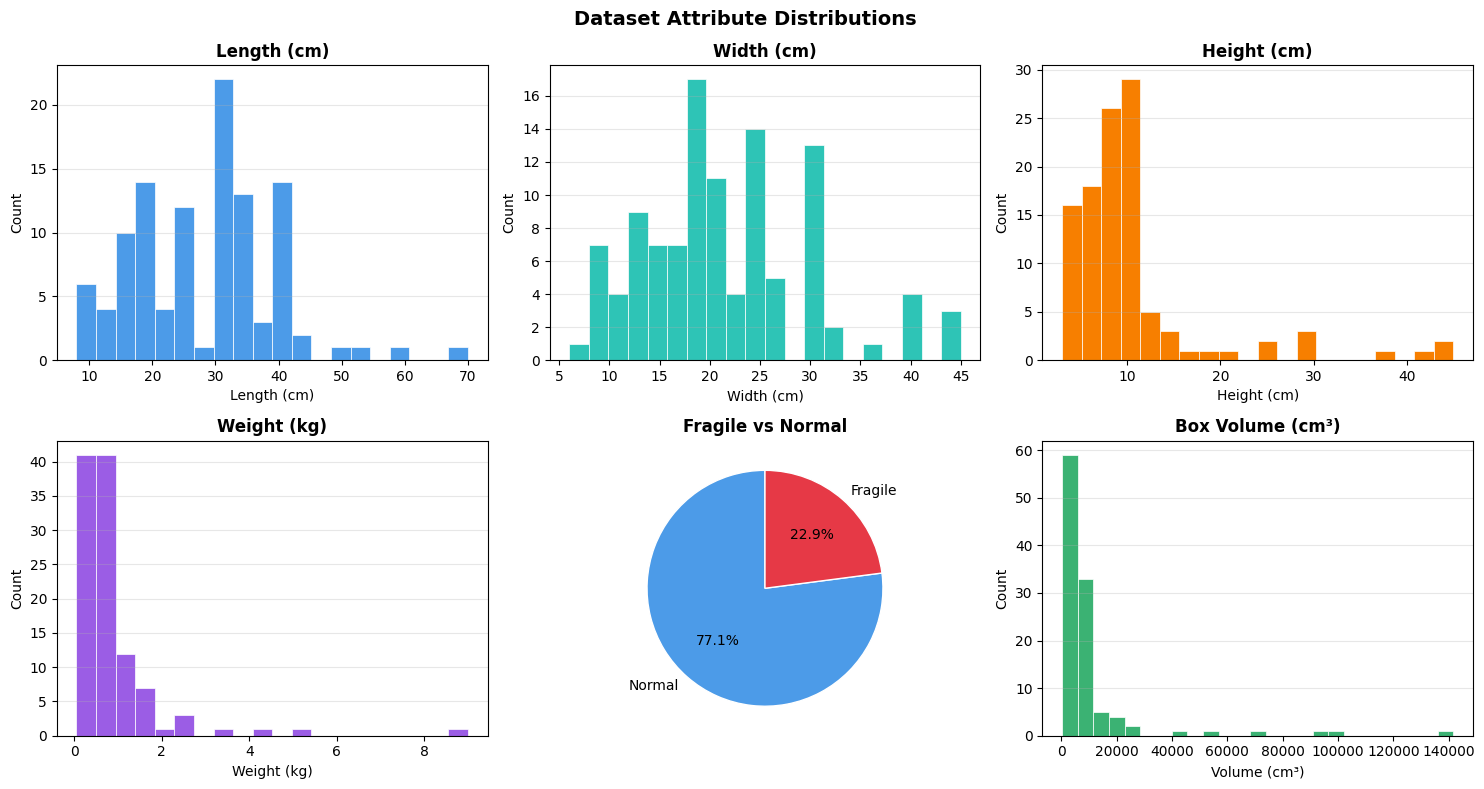

Figure saved → Statistics/dataset_distributions.png


In [30]:
# ── Distribution plots ───────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle("Dataset Attribute Distributions", fontsize=14, fontweight='bold')

attrs   = ['Length_cm', 'Width_cm', 'Height_cm', 'Weight_kg']
colours = ['#4C9BE8', '#2EC4B6', '#F77F00', '#9B5DE5']
labels  = ['Length (cm)', 'Width (cm)', 'Height (cm)', 'Weight (kg)']

for ax, attr, colour, label in zip(axes.flat, attrs, colours, labels):
    ax.hist(df[attr], bins=20, color=colour, edgecolor='white', linewidth=0.5)
    ax.set_title(label, fontweight='bold')
    ax.set_xlabel(label)
    ax.set_ylabel("Count")
    ax.grid(axis='y', alpha=0.3)

# Fragile pie chart
ax_pie = axes[1, 1]
counts = df['fragile_flag'].value_counts()
ax_pie.pie(counts, labels=['Normal','Fragile'], autopct='%1.1f%%',
           colors=['#4C9BE8','#E63946'], startangle=90,
           wedgeprops=dict(edgecolor='white'))
ax_pie.set_title("Fragile vs Normal", fontweight='bold')

# Volume distribution (log scale)
ax_vol = axes[1, 2]
df['Volume_cm3'] = df['Length_cm'] * df['Width_cm'] * df['Height_cm']
ax_vol.hist(df['Volume_cm3'], bins=25, color='#3BB273', edgecolor='white', linewidth=0.5)
ax_vol.set_title("Box Volume (cm³)", fontweight='bold')
ax_vol.set_xlabel("Volume (cm³)")
ax_vol.set_ylabel("Count")
ax_vol.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(r"Statistics\dataset_distributions.png", dpi=120, bbox_inches='tight')
plt.show()
print("Figure saved → Statistics/dataset_distributions.png")


---
<a id='3'></a>
## 3. Dependencies & Setup


In [31]:
# ── Install / verify required libraries ──────────────────────────────────────
# All libraries below are part of the standard scientific Python stack.
# If any are missing in your environment, uncomment and run the pip line.

# !pip install matplotlib plotly numpy pandas

import sys, platform
print(f"Python  : {sys.version}")
print(f"Platform: {platform.platform()}")

import matplotlib ; print(f"matplotlib : {matplotlib.__version__}")
import numpy      ; print(f"numpy      : {numpy.__version__}")
import pandas     ; print(f"pandas     : {pandas.__version__}")
try:
    import plotly ; print(f"plotly     : {plotly.__version__}")
except ImportError:
    print("plotly     : NOT INSTALLED (interactive 3D views will be skipped)")


Python  : 3.13.11 | packaged by Anaconda, Inc. | (main, Dec 10 2025, 21:21:58) [MSC v.1929 64 bit (AMD64)]
Platform: Windows-10-10.0.19045-SP0
matplotlib : 3.10.9
numpy      : 2.4.5
pandas     : 3.0.3
plotly     : 6.7.0


---
<a id='4'></a>
## 4. Shared Data Model: `Box` and `Container`

Both classes are shared verbatim across all three algorithms to guarantee  
that comparisons are fair and that no algorithmic advantage is introduced  
through different representations.

### `Box`
Stores the original dimensions (L, W, H), weight, fragile flag, and — once placed —  
the 3D position and rotation index.  

**Rotation system:** 6 distinct orientations map the box's L×W×H to the container's X, Y, Z axes.  
Fragile boxes are restricted to orientations 0 and 2 (upright orientations only).

### `Container`
Holds the list of placed boxes together with running totals of occupied volume and weight.


In [32]:
# ═══════════════════════════════════════════════════════════════════════════
#  SHARED DATA MODEL  —  Box & Container
# ═══════════════════════════════════════════════════════════════════════════

class Box:
    """Represents a single package to be packed into the container."""

    def __init__(self, box_id, length, width, height, weight, fragile=0):
        if length <= 0 or width <= 0 or height <= 0:
            raise ValueError("Dimensions must be positive")
        if weight < 0:
            raise ValueError("Weight cannot be negative")
        if fragile not in (0, 1):
            raise ValueError("fragile must be 0 or 1")

        self.id      = box_id
        self.L       = length   # original X dimension
        self.W       = width    # original Y dimension
        self.H       = height   # original Z dimension
        self.weight  = weight
        self.fragile = fragile

        self.volume   = self.L * self.W * self.H
        self.position = None   # (x, y, z) once placed
        self.rotation = None   # rotation index 0-5 once placed
        self.placed   = False

    # ── Rotations ────────────────────────────────────────────────────────────
    def get_possible_rotations(self):
        """Return all 6 axis-aligned orientations as (dx, dy, dz) tuples."""
        return [
            (self.L, self.W, self.H),   # 0 — natural
            (self.L, self.H, self.W),   # 1
            (self.W, self.L, self.H),   # 2
            (self.W, self.H, self.L),   # 3
            (self.H, self.L, self.W),   # 4
            (self.H, self.W, self.L),   # 5
        ]

    def get_rotation_dims(self):
        """Effective (dx, dy, dz) after the current rotation is applied."""
        if self.rotation is None:
            return (self.L, self.W, self.H)
        rots = self.get_possible_rotations()
        if not (0 <= self.rotation < len(rots)):
            raise ValueError("Invalid rotation index")
        return rots[self.rotation]

    # ── Helpers ──────────────────────────────────────────────────────────────
    def get_dims(self):
        return (self.L, self.W, self.H)

    def base_area(self):
        return self.L * self.W

    def get_center(self):
        """3D centroid of the box once placed."""
        if self.position is None or self.rotation is None:
            return None
        x, y, z = self.position
        dx, dy, dz = self.get_rotation_dims()
        return (x + dx / 2, y + dy / 2, z + dz / 2)

    def reset(self):
        """Clear placement state (used before each new packing attempt)."""
        self.position = None
        self.rotation = None
        self.placed   = False

    def __repr__(self):
        pos = self.position if self.position is not None else "Not placed"
        rot = self.rotation if self.rotation is not None else "None"
        return (f"Box(id={self.id}, dims=({self.L}×{self.W}×{self.H}), "
                f"weight={self.weight}kg, fragile={self.fragile}, "
                f"placed={self.placed}, pos={pos}, rot={rot})")


class Container:
    """The truck cargo space: a rectangular 3D bin."""

    def __init__(self, length, width, height, max_weight=float('inf')):
        if length <= 0 or width <= 0 or height <= 0:
            raise ValueError("Container dimensions must be positive")
        if max_weight < 0:
            raise ValueError("max_weight cannot be negative")

        self.L = length   # X
        self.W = width    # Y
        self.H = height   # Z
        self.max_weight = max_weight

        self.volume          = self.L * self.W * self.H
        self.boxes           = []
        self.occupied_volume = 0.0
        self.occupied_weight = 0.0

    def add_box(self, box, position=None, rotation=None):
        box.position = position
        box.rotation = rotation
        box.placed   = True
        self.boxes.append(box)
        self.occupied_volume += box.volume
        self.occupied_weight += box.weight

    def remove_box(self, box):
        if box in self.boxes:
            self.boxes.remove(box)
            self.occupied_volume -= box.volume
            self.occupied_weight -= box.weight
            box.reset()

    def reset(self):
        """Remove all boxes and reset running totals."""
        for box in self.boxes:
            box.reset()
        self.boxes.clear()
        self.occupied_volume = 0.0
        self.occupied_weight = 0.0

    def __repr__(self):
        return (f"Container(dims=({self.L}×{self.W}×{self.H}), "
                f"boxes={len(self.boxes)}, "
                f"vol={self.occupied_volume:.0f}/{self.volume} cm³, "
                f"weight={self.occupied_weight:.2f} kg)")


print("✔  Box and Container classes defined.")
print(f"   Example: {Box(1, 30, 20, 15, 1.5, fragile=0)}")
print(f"   Example: {Container(160, 105, 80)}")


✔  Box and Container classes defined.
   Example: Box(id=1, dims=(30×20×15), weight=1.5kg, fragile=0, placed=False, pos=Not placed, rot=None)
   Example: Container(dims=(160×105×80), boxes=0, vol=0/1344000 cm³, weight=0.00 kg)


---
<a id='5'></a>
## 5. Shared Utilities

### 5.1 Constraint Functions
All three algorithms delegate validity checking to the same functions,  
ensuring that the comparison is based purely on search strategy, not on  
different physical models.

### 5.2 Objective Function
The objective function **f(S)** maps a packing state *S* to a score in **[0, 100]**:

$$f(S) = \alpha \cdot \text{VolUtil}(S) + (1-\alpha) \cdot \text{Stability}(S) \cdot 100 - l \cdot P(S)$$

| Term | Meaning |
|---|---|
| **VolUtil** | Volume utilisation: `occupied_volume / container_volume × 100` |
| **Stability** | Centre-of-mass score [0,1]: rewards low CoM-Z (70%), and centred CoM-XY (30%) |
| **P(S)** | Volume-proportional penalty for unplaced boxes |
| **α = 0.6** | Prioritises space efficiency over stability |
| **l = 0.15** | Penalty weight |

### 5.3 Visualisation
Two visualisation modes are available:
- `visualize_packing()` — static 3D Matplotlib figure (saved as PNG)
- `visualize_packing_html()` — interactive Plotly HTML with solid/X-ray toggle and camera presets


In [33]:
# ═══════════════════════════════════════════════════════════════════════════
#  SHARED UTILITIES
# ═══════════════════════════════════════════════════════════════════════════

# ── Rotation helpers ─────────────────────────────────────────────────────────

def get_allowed_rotations(box):
    """Fragile boxes are restricted to upright orientations (indices 0 and 2)."""
    return [0, 2] if box.fragile == 1 else [0, 1, 2, 3, 4, 5]


def get_effective_rotations(box):
    """Deduplicate rotations that yield the same (dx,dy,dz) — avoids redundant checks."""
    seen, unique = set(), []
    for i in get_allowed_rotations(box):
        dims = box.get_possible_rotations()[i]
        if dims not in seen:
            unique.append(i)
            seen.add(dims)
    return unique


# ── Geometric constraint functions ───────────────────────────────────────────

def is_inside_container(box, container):
    """True iff the box (with current position & rotation) fits within bounds."""
    if box.position is None:
        return False
    x, y, z = box.position
    dx, dy, dz = box.get_rotation_dims()
    return (x >= 0 and x + dx <= container.L and
            y >= 0 and y + dy <= container.W and
            z >= 0 and z + dz <= container.H)


def boxes_overlap(a, b):
    """True iff two placed boxes share interior volume."""
    ax, ay, az = a.position;  adx, ady, adz = a.get_rotation_dims()
    bx, by, bz = b.position;  bdx, bdy, bdz = b.get_rotation_dims()
    return (ax < bx + bdx and bx < ax + adx and
            ay < by + bdy and by < ay + ady and
            az < bz + bdz and bz < az + adz)


def has_no_overlap(new_box, container):
    return all(not boxes_overlap(new_box, b) for b in container.boxes)


def fragile_constraint(box, position, container):
    """
    Returns True (VIOLATED) if:
      - placing *box* would sit on top of a fragile box, OR
      - a non-fragile *box* would be placed above a fragile one.
    """
    x, y, z = position
    ndx, ndy, _ = box.get_rotation_dims()
    for b in container.boxes:
        bx, by, bz = b.position;  bdx, bdy, bdz = b.get_rotation_dims()
        if b.fragile == 1 and abs(z - (bz + bdz)) < 0.01:
            ox = max(0, min(x + ndx, bx + bdx) - max(x, bx))
            oy = max(0, min(y + ndy, by + bdy) - max(y, by))
            if ox > 0 and oy > 0:
                return True   # would stack on a fragile box
        if b.fragile == 1 and box.fragile == 0:
            if z >= (bz + bdz) - 0.01:
                return True
    return False


def is_supported(box, position, container, min_ratio=0.70):
    """
    True iff at least *min_ratio* of the box's base is supported.
    Boxes resting on the floor (z ≈ 0) are always supported.
    """
    x, y, z = position;  dx, dy, _ = box.get_rotation_dims()
    if abs(z) < 0.01:
        return True
    supported = 0.0
    for b in container.boxes:
        bx, by, bz = b.position;  bdx, bdy, bdz = b.get_rotation_dims()
        if abs((bz + bdz) - z) < 0.01:
            supported += (max(0, min(x + dx, bx + bdx) - max(x, bx)) *
                          max(0, min(y + dy, by + bdy) - max(y, by)))
    return (supported / (dx * dy)) >= min_ratio


def can_place(box, position, rotation, container):
    """Master validity gate — passes all four constraints."""
    box.position = position
    box.rotation = rotation
    ok = (is_inside_container(box, container)
          and has_no_overlap(box, container)
          and not fragile_constraint(box, position, container)
          and is_supported(box, position, container))
    box.position = None
    box.rotation = None
    return ok


def can_fit_any_rotation(box, ep, container):
    """Quick boundary rejection before running full constraint checks."""
    x, y, z = ep
    return any(x + dx <= container.L and y + dy <= container.W and z + dz <= container.H
               for dx, dy, dz in box.get_possible_rotations())


# ── Objective function ────────────────────────────────────────────────────────

def volume_utilization(container):
    """Volume utilisation in percent [0, 100]."""
    return (container.occupied_volume / container.volume) * 100


def stability_score(container):
    """
    Centre-of-Mass stability score in [0, 1].
    1.0 = CoM at floor level, centred laterally, near the driver's wall.
    Weights: 70% vertical (Z) + 30% horizontal (XY).
    """
    if not container.boxes:
        return 1.0
    total_w = container.occupied_weight
    if total_w == 0:
        return 1.0

    wx = wy = wz = 0.0
    for b in container.boxes:
        dx, dy, dz = b.get_rotation_dims()
        cx = b.position[0] + dx / 2
        cy = b.position[1] + dy / 2
        cz = b.position[2] + dz / 2
        wx += b.weight * cx
        wy += b.weight * cy
        wz += b.weight * cz

    com_x, com_y, com_z = wx / total_w, wy / total_w, wz / total_w

    z_score  = 1.0 - (com_z / container.H)
    x_offset = com_x / container.L
    y_offset = abs(com_y - container.W / 2) / (container.W / 2)
    xy_score = 1.0 - ((x_offset + y_offset) / 2.0)

    return round(0.7 * z_score + 0.3 * xy_score, 4)


def objective(container, alpha=0.6, unplaced_boxes=None, total_boxes=None, penalty_weight=0.15):
    """
    Combined packing quality score ∈ [0, 100].
    f = α·VolUtil + (1-α)·Stability×100  −  penalty_weight·UnplacedVolRatio×100
    """
    util  = volume_utilization(container)
    stab  = stability_score(container) * 100
    score = alpha * util + (1 - alpha) * stab

    if unplaced_boxes and total_boxes:
        unplaced_vol_ratio = min(sum(b.volume for b in unplaced_boxes) / container.volume, 1.0)
        score -= penalty_weight * unplaced_vol_ratio * 100

    return max(score, 0.0)


print("✔  Constraint functions defined.")
print("✔  Objective function defined.")
print(f"   Test container (empty): util={volume_utilization(Container(160,105,80)):.1f}%, "
      f"stability={stability_score(Container(160,105,80)):.4f}")


✔  Constraint functions defined.
✔  Objective function defined.
   Test container (empty): util=0.0%, stability=1.0000


In [34]:
# ── CSV loader ────────────────────────────────────────────────────────────────

def load_boxes_from_csv(filepath):
    """
    Load boxes from a CSV file with columns:
    ID, Length_cm, Width_cm, Height_cm, Weight_kg, fragile_flag
    Returns a list of Box objects.
    """
    df = pd.read_csv(filepath, on_bad_lines='skip', engine='python')
    df.columns = df.columns.str.strip()
    required = ['ID', 'Length_cm', 'Width_cm', 'Height_cm', 'Weight_kg', 'fragile_flag']
    df = df.dropna(subset=required)
    boxes = [
        Box(int(r['ID']), float(r['Length_cm']), float(r['Width_cm']),
            float(r['Height_cm']), float(r['Weight_kg']), int(r['fragile_flag']))
        for _, r in df.iterrows()
    ]
    print(f"Loaded {len(boxes)} boxes  "
          f"| Non-fragile: {sum(1 for b in boxes if b.fragile==0)}  "
          f"| Fragile: {sum(1 for b in boxes if b.fragile==1)}")
    return boxes


# Pre-load boxes once — reused by all algorithms
ALL_BOXES = load_boxes_from_csv(DATA_PATH)
CONTAINER_DIMS = dict(length=160, width=105, height=80)


Loaded 109 boxes  | Non-fragile: 84  | Fragile: 25


In [35]:
# ── Visualisation helpers ─────────────────────────────────────────────────────
import os

NORMAL_COLOURS = [
    '#4C9BE8','#2EC4B6','#6C63FF','#F77F00','#3BB273',
    '#E07A5F','#81B29A','#9B5DE5','#00BBF9','#F15BB5',
]

def visualize_packing(container, packed_boxes, title="Packing Visualisation", save_path=None):
    """
    Static 3D Matplotlib figure.
    - Fragile boxes → RED
    - Normal boxes  → rotating colour palette
    - Container     → grey wireframe
    """
    from mpl_toolkits.mplot3d import Axes3D          # noqa
    from mpl_toolkits.mplot3d.art3d import Poly3DCollection

    def _faces(x, y, z, dx, dy, dz):
        v = [(x,y,z),(x+dx,y,z),(x+dx,y+dy,z),(x,y+dy,z),
             (x,y,z+dz),(x+dx,y,z+dz),(x+dx,y+dy,z+dz),(x,y+dy,z+dz)]
        return [[v[0],v[1],v[2],v[3]],[v[4],v[5],v[6],v[7]],
                [v[0],v[1],v[5],v[4]],[v[3],v[2],v[6],v[7]],
                [v[0],v[3],v[7],v[4]],[v[1],v[2],v[6],v[5]]]

    def _wireframe(ax, L, W, H):
        c = [(0,0,0),(L,0,0),(L,W,0),(0,W,0),(0,0,H),(L,0,H),(L,W,H),(0,W,H)]
        for a,b in [(0,1),(1,2),(2,3),(3,0),(4,5),(5,6),(6,7),(7,4),
                    (0,4),(1,5),(2,6),(3,7)]:
            ax.plot([c[a][0],c[b][0]],[c[a][1],c[b][1]],[c[a][2],c[b][2]],
                    color='#888', linewidth=1.2, alpha=0.4)

    fig = plt.figure(figsize=(14,9))
    fig.patch.set_facecolor('#1A1A2E')
    ax  = fig.add_subplot(111, projection='3d')
    ax.set_facecolor('#16213E')
    _wireframe(ax, container.L, container.W, container.H)

    col_idx = 0
    for box in packed_boxes:
        x, y, z   = box.position
        dx, dy, dz = box.get_rotation_dims()
        fc = '#E63946' if box.fragile else NORMAL_COLOURS[col_idx % len(NORMAL_COLOURS)]
        ec = '#FF6B6B' if box.fragile else '#FFFFFF'
        if not box.fragile:
            col_idx += 1
        poly = Poly3DCollection(_faces(x,y,z,dx,dy,dz), alpha=0.72,
                                linewidths=0.4, edgecolors=ec)
        poly.set_facecolor(fc)
        ax.add_collection3d(poly)
        ax.text(x+dx/2, y+dy/2, z+dz/2, str(box.id),
                ha='center', va='center',
                fontsize=max(4,min(8,min(dx,dy,dz)*0.35)),
                color='white', fontweight='bold')

    ax.set_xlim(0, container.L); ax.set_ylim(0, container.W); ax.set_zlim(0, container.H)
    ax.set_xlabel('X (cm)'); ax.set_ylabel('Y (cm)'); ax.set_zlabel('Z (cm)')
    ax.set_title(f"{title}\nPacked: {len(packed_boxes)} | "
                 f"Vol: {volume_utilization(container):.1f}% | "
                 f"Fragile: {sum(1 for b in packed_boxes if b.fragile)}",
                 color='white', fontsize=11)
    handles = [mpatches.Patch(facecolor='#4C9BE8', label='Normal'),
               mpatches.Patch(facecolor='#E63946', label='Fragile')]
    ax.legend(handles=handles, facecolor='#1A1A2E', labelcolor='white')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=130, bbox_inches='tight', facecolor=fig.get_facecolor())
        print(f"  Saved → {save_path}")
    plt.show()


def visualize_packing_html(container, packed_boxes, title="Packing", save_path="packing.html"):
    """Interactive Plotly 3D visualisation with solid/X-ray toggle."""
    try:
        import plotly.graph_objects as go
    except ImportError:
        print("[!] plotly not installed — skipping interactive visualisation.")
        return

    SOLID, XRAY = 1.0, 0.28

    def _mesh(x,y,z,dx,dy,dz,color,hover,opacity=SOLID):
        vx=[x,x+dx,x+dx,x,x,x+dx,x+dx,x]
        vy=[y,y,y+dy,y+dy,y,y,y+dy,y+dy]
        vz=[z,z,z,z,z+dz,z+dz,z+dz,z+dz]
        i=[0,0,4,4,0,0,2,2,0,0,1,1]
        j=[1,2,5,6,1,5,3,7,3,7,2,6]
        k=[2,3,6,7,5,4,7,6,7,4,6,5]
        return go.Mesh3d(x=vx,y=vy,z=vz,i=i,j=j,k=k,color=color,
                         opacity=opacity,flatshading=True,showlegend=False,
                         hovertemplate=hover+'<extra></extra>',
                         lighting=dict(ambient=0.6,diffuse=0.85))

    def _wire(x,y,z,dx,dy,dz,color,w=1.2):
        c=[(x,y,z),(x+dx,y,z),(x+dx,y+dy,z),(x,y+dy,z),
           (x,y,z+dz),(x+dx,y,z+dz),(x+dx,y+dy,z+dz),(x,y+dy,z+dz)]
        ex,ey,ez=[],[],[]
        for a,b in [(0,1),(1,2),(2,3),(3,0),(4,5),(5,6),(6,7),(7,4),(0,4),(1,5),(2,6),(3,7)]:
            ex+=[c[a][0],c[b][0],None]; ey+=[c[a][1],c[b][1],None]; ez+=[c[a][2],c[b][2],None]
        return go.Scatter3d(x=ex,y=ey,z=ez,mode='lines',
                            line=dict(color=color,width=w),showlegend=False,hoverinfo='skip')

    traces=[]; mesh_idxs=[]; ci=0; lf=ln=False
    traces.append(_wire(0,0,0,container.L,container.W,container.H,'rgba(200,200,200,0.5)',2.5))

    for box in packed_boxes:
        x,y,z=box.position; dx,dy,dz=box.get_rotation_dims()
        frag=box.fragile==1
        fc='#E63946' if frag else NORMAL_COLOURS[ci%len(NORMAL_COLOURS)]
        if not frag: ci+=1
        hover=(f"<b>Box {box.id}</b><br>Dims: {dx:.0f}×{dy:.0f}×{dz:.0f}<br>"
               f"Weight: {box.weight}kg<br>Fragile: {'Yes' if frag else 'No'}")
        m=_mesh(x,y,z,dx,dy,dz,fc,hover,SOLID)
        m.showlegend=(frag and not lf) or (not frag and not ln)
        m.name='Fragile ⚠️' if frag else 'Normal'
        if frag: lf=True
        else:    ln=True
        mesh_idxs.append(len(traces)); traces.append(m)
        traces.append(_wire(x,y,z,dx,dy,dz,'#FFFFFF' if not frag else '#FF6B6B'))
        traces.append(go.Scatter3d(x=[x+dx/2],y=[y+dy/2],z=[z+dz/2],mode='text',
                                   text=[str(box.id)],showlegend=False,hoverinfo='skip',
                                   textfont=dict(size=max(7,min(11,min(dx,dy,dz)*0.4)),color='white')))

    n=len(traces)
    s_op=[None]*n; x_op=[None]*n
    for idx in mesh_idxs: s_op[idx]=SOLID; x_op[idx]=XRAY

    util=volume_utilization(container); stab=stability_score(container)
    fig=go.Figure(data=traces)
    fig.update_layout(
        title=dict(text=f"<b>{title}</b><br><span style='font-size:11px;color:#aaa'>"
                   f"Packed: {len(packed_boxes)} | {util:.1f}% vol | "
                   f"Stability: {stab:.3f}</span>",
                   font=dict(color='white',size=13),x=0.5,y=0.97),
        paper_bgcolor='#1A1A2E',
        scene=dict(bgcolor='#16213E',
                   xaxis=dict(title='X (cm)',range=[0,container.L],color='#AAA',
                              showbackground=True,backgroundcolor='#16213E'),
                   yaxis=dict(title='Y (cm)',range=[0,container.W],color='#AAA',
                              showbackground=True,backgroundcolor='#16213E'),
                   zaxis=dict(title='Z (cm)',range=[0,container.H],color='#AAA',
                              showbackground=True,backgroundcolor='#16213E'),
                   aspectmode='data',camera=dict(eye=dict(x=1.6,y=-1.8,z=1.2))),
        legend=dict(bgcolor='rgba(26,26,46,0.9)',bordercolor='#555',
                    borderwidth=1,font=dict(color='white',size=11),x=0.01,y=0.99),
        margin=dict(l=0,r=0,t=70,b=0),
        updatemenus=[dict(type='buttons',direction='left',x=0.01,y=0.92,
                          xanchor='left',yanchor='top',bgcolor='#2A2A4E',
                          bordercolor='#555',font=dict(color='white',size=11),
                          buttons=[dict(label='Solid',method='restyle',
                                        args=[{'opacity':s_op}]),
                                   dict(label='X-Ray',method='restyle',
                                        args=[{'opacity':x_op}])])])

    abs_path=os.path.abspath(save_path)
    fig.write_html(abs_path,include_plotlyjs='cdn')
    print(f"  Interactive HTML saved → {abs_path}")
    fig.show()


print("✔  Visualisation helpers defined.")


✔  Visualisation helpers defined.


---
<a id='6'></a>
## 6. Algorithm 1 — Greedy Heuristic

### Design
The greedy algorithm is a single-pass, deterministic heuristic.  
It never backtracks: each box is evaluated once and either placed or discarded.

**Key design choices:**

| Choice | Rationale |
|---|---|
| Non-fragile boxes placed first (sorted by volume ↓) | Large stable boxes form the structural foundation |
| Fragile boxes placed last (sorted by base area ↓) | They must rest on top with nothing above them |
| Extreme-Point (EP) candidate positions | More efficient than a voxel grid; EPs grow from box corners |
| Phase 1 — Priority stacking (below height limit) | Builds compact columnar stacks early |
| Phase 2 — Maximum Contact Score (MCS) fill | Fills gaps by maximising surface contact |
| Reorder window (≤8 packed boxes) | Local reordering of small subsets to recover missed placements |

**Contact score** rewards surface contact with the floor, container walls,  
and neighbouring boxes, producing tightly packed, stable configurations.

**Complexity:** O(n · |EP| · rotations) per box, where |EP| grows with packing density.


In [36]:
# ═══════════════════════════════════════════════════════════════════════════
#  ALGORITHM 1 — GREEDY HEURISTIC  (Extreme-Point + Contact Score)
# ═══════════════════════════════════════════════════════════════════════════

import copy, time
from itertools import combinations

# ── Hyper-parameters ─────────────────────────────────────────────────────────
REORDER_THRESHOLD  = 8     # max packed boxes before reorder is skipped
MAX_SUBSET_SIZE    = 2     # max subset size for local reorder search
MAX_REORDER_TIME   = 0.3   # time budget for reorder step (seconds)
MAX_EPS            = 150   # maximum extreme points to track
HEIGHT_LIMIT_RATIO = 0.65  # Phase-1 height ceiling as fraction of container height


# ── Extreme-Point helpers ─────────────────────────────────────────────────────

def generate_extreme_points(box, container):
    """Generate 3 new EP candidates from the outer faces of a newly placed box."""
    x, y, z = box.position;  dx, dy, dz = box.get_rotation_dims()
    candidates = [(x+dx, y, z), (x, y+dy, z), (x, y, z+dz)]
    return [(ex, ey, ez) for ex, ey, ez in candidates
            if 0 <= ex < container.L and 0 <= ey < container.W and 0 <= ez < container.H]


def get_all_extreme_points(container):
    """Collect and cap all active extreme points."""
    eps = [(0, 0, 0)]
    for b in container.boxes:
        eps.extend(generate_extreme_points(b, container))
    eps = list(set(eps))
    if len(eps) > MAX_EPS:
        eps = sorted(eps, key=lambda p: (p[2], p[1], p[0]))[:MAX_EPS]
    return eps


# ── Scoring helpers ──────────────────────────────────────────────────────────

def contact_score(box, position, container):
    """
    Surface-contact score: rewards contact with floor, walls, and neighbouring boxes.
    Higher → more compact, more stable placement.
    """
    x, y, z = position;  dx, dy, dz = box.get_rotation_dims()
    score = 0.0

    # Floor contact
    if abs(z) < 0.01:
        score += dx * dy

    # Top-face contact with boxes below
    for b in container.boxes:
        bx, by, bz = b.position;  bdx, bdy, bdz = b.get_rotation_dims()
        if abs((bz + bdz) - z) < 0.01:
            score += (max(0, min(x+dx, bx+bdx) - max(x, bx)) *
                      max(0, min(y+dy, by+bdy) - max(y, by)))

    # Wall contact
    if abs(x)           < 0.01: score += dy * dz
    if abs(x+dx-container.L) < 0.01: score += dy * dz
    if abs(y)           < 0.01: score += dx * dz
    if abs(y+dy-container.W) < 0.01: score += dx * dz

    # Side-face contact with adjacent boxes
    for b in container.boxes:
        bx, by, bz = b.position;  bdx, bdy, bdz = b.get_rotation_dims()
        if abs((bx+bdx)-x) < 0.01 or abs((x+dx)-bx) < 0.01:
            score += (max(0, min(y+dy,by+bdy)-max(y,by)) *
                      max(0, min(z+dz,bz+bdz)-max(z,bz)))
        if abs((by+bdy)-y) < 0.01 or abs((y+dy)-by) < 0.01:
            score += (max(0, min(x+dx,bx+bdx)-max(x,bx)) *
                      max(0, min(z+dz,bz+bdz)-max(z,bz)))
    return score


def surface_dims_at(position, container):
    x, y, z = position
    for b in container.boxes:
        bx, by, bz = b.position;  bdx, bdy, bdz = b.get_rotation_dims()
        if abs((bz+bdz)-z) < 0.01 and bx <= x < bx+bdx and by <= y < by+bdy:
            return bdx, bdy
    if abs(z) < 0.01:
        return container.L, container.W
    return 0, 0


def stacking_priority(box, rot, pos, container):
    """Priority 1=fits fully on surface, 2=larger than surface, 3=partially off."""
    ndx, ndy, _ = box.get_possible_rotations()[rot]
    sdx, sdy    = surface_dims_at(pos, container)
    if sdx > 0 and ndx <= sdx and ndy <= sdy:  return 1
    if sdx > 0 and sdx <= ndx and sdy <= ndy:  return 2
    return 3


# ── Phase-1: Priority stacking ────────────────────────────────────────────────

def find_best_stack(box, container, eps, height_limit):
    best, best_score, best_priority = None, -1, 99
    for pos in eps:
        if pos[2] >= height_limit:
            continue
        if not can_fit_any_rotation(box, pos, container):
            continue
        for rot in get_effective_rotations(box):
            _, _, dz = box.get_possible_rotations()[rot]
            if pos[2] + dz > height_limit * 1.15:
                continue
            if not can_place(box, pos, rot, container):
                continue
            priority = stacking_priority(box, rot, pos, container)
            box.position = pos;  box.rotation = rot
            score = contact_score(box, pos, container)
            box.position = None; box.rotation = None
            if priority < best_priority or (priority == best_priority and score > best_score):
                best = (pos, rot);  best_score = score;  best_priority = priority
    return best, best_score


# ── Phase-2: Gap filling (MCS) ────────────────────────────────────────────────

def find_best_fill(box, container, eps):
    """Fill lowest-Z gaps first; break ties via contact score."""
    best, best_score = None, -1
    sorted_eps = sorted(eps, key=lambda p: (p[2], -(p[0]+p[1])))
    for pos in sorted_eps:
        if not can_fit_any_rotation(box, pos, container):
            continue
        for rot in get_effective_rotations(box):
            if not can_place(box, pos, rot, container):
                continue
            box.position = pos;  box.rotation = rot
            x, y, z = pos;  dx, dy, dz = box.get_rotation_dims()
            score = contact_score(box, pos, container)
            # Horizontal layer bonus
            same_z = sum(1 for b in container.boxes if abs(b.position[2]-z) < 0.01)
            score += same_z * 5
            # Corner bonuses
            if abs(x) < 0.01:             score += dy * dz
            if abs(x+dx-container.L) < 0.01: score += dy * dz
            if abs(y) < 0.01:             score += dx * dz
            if abs(y+dy-container.W) < 0.01: score += dx * dz
            box.position = None;  box.rotation = None
            if score > best_score:
                best = (pos, rot);  best_score = score
    return best, best_score


# ── Reorder helpers ───────────────────────────────────────────────────────────

def evaluate_reorder(new_box, subset, container):
    all_boxes = sorted(list(subset) + [new_box], key=lambda b: b.L*b.W, reverse=True)
    total_contact, sim_z = 0.0, 0.0
    for i, b in enumerate(all_boxes):
        dx, dy, dz = b.get_dims()
        if i == 0:
            total_contact += dx * dy
        else:
            pdx, pdy, _ = all_boxes[i-1].get_dims()
            total_contact += max(0, min(dx,pdx)) * max(0, min(dy,pdy))
        sim_z += dz
        if sim_z > container.H:
            return -1
    return total_contact


def apply_reorder(new_box, subset, container, packed):
    all_boxes = sorted(list(subset) + [new_box], key=lambda b: b.L*b.W, reverse=True)
    for b in subset:
        container.remove_box(b)
        if b in packed:
            packed.remove(b)
    eps = get_all_extreme_points(container)
    for b in all_boxes:
        result, _ = find_best_fill(b, container, sorted(eps, key=lambda p: (p[2],p[1],p[0])))
        if result:
            pos, rot = result
            container.add_box(b, pos, rot)
            packed.append(b)
            eps.extend(generate_extreme_points(b, container))
            eps = list(set(eps))
            if len(eps) > MAX_EPS:
                eps = sorted(eps, key=lambda p: (p[2],p[1],p[0]))[:MAX_EPS]


# ── Main greedy packer ────────────────────────────────────────────────────────

def greedy_contact(boxes, container):
    """
    Two-phase greedy packer.
    Phase 1: stack non-fragile boxes up to HEIGHT_LIMIT_RATIO of container height.
    Phase 2: fill remaining gaps using Maximum Contact Score.
    Fragile boxes are placed last, on top, using DBLF order.
    """
    for b in boxes:
        b.reset()

    height_limit = container.H * HEIGHT_LIMIT_RATIO
    non_fragile  = sorted([b for b in boxes if b.fragile == 0],
                          key=lambda b: b.volume, reverse=True)
    fragile      = sorted([b for b in boxes if b.fragile == 1],
                          key=lambda b: b.L*b.W, reverse=True)
    packed, unpacked = [], []

    # Seed box: largest non-fragile placed at the origin
    if non_fragile:
        seed = non_fragile.pop(0)
        placed = False
        for rot in get_effective_rotations(seed):
            if can_place(seed, (0,0,0), rot, container):
                container.add_box(seed, (0,0,0), rot)
                packed.append(seed)
                placed = True
                break
        if not placed:
            unpacked.append(seed)

    for box in non_fragile:
        eps = get_all_extreme_points(container)
        n   = len(packed)
        placed = False

        if n <= REORDER_THRESHOLD:
            best_pos, best_rot, best_score = None, None, -1
            best_reorder = None
            result, score = find_best_stack(box, container, eps, height_limit)
            if result:
                best_pos, best_rot = result;  best_score = score
            t_start = time.time()
            for size in range(1, min(n, MAX_SUBSET_SIZE) + 1):
                if time.time() - t_start > MAX_REORDER_TIME:
                    break
                for subset in combinations(packed, size):
                    if time.time() - t_start > MAX_REORDER_TIME:
                        break
                    rs = evaluate_reorder(box, subset, container)
                    if rs > best_score:
                        best_score = rs;  best_reorder = subset;  best_pos = best_rot = None
            if best_reorder:
                apply_reorder(box, best_reorder, container, packed)
                placed = True
            elif best_pos is not None:
                container.add_box(box, best_pos, best_rot)
                packed.append(box)
                placed = True
        else:
            result, _ = find_best_stack(box, container, eps, height_limit)
            if result:
                pos, rot = result
                container.add_box(box, pos, rot)
                packed.append(box)
                placed = True

        if not placed:
            result, _ = find_best_fill(box, container, eps)
            if result:
                pos, rot = result
                container.add_box(box, pos, rot)
                packed.append(box)
                placed = True

        if not placed:
            unpacked.append(box)

    # Fragile boxes — top-down DBLF
    for box in fragile:
        eps = get_all_extreme_points(container)
        sorted_eps = sorted(eps, key=lambda p: (-p[2], p[1], p[0]))
        result, _ = find_best_fill(box, container, sorted_eps)
        if result:
            pos, rot = result
            container.add_box(box, pos, rot)
            packed.append(box)
        else:
            unpacked.append(box)

    score = objective(container, alpha=0.6, unplaced_boxes=unpacked, total_boxes=len(boxes))
    return packed, unpacked, score


print("✔  Greedy algorithm defined.")


✔  Greedy algorithm defined.


In [37]:
# ── Run Greedy ────────────────────────────────────────────────────────────────
import copy

greedy_boxes  = [copy.deepcopy(b) for b in ALL_BOXES]
greedy_cont   = Container(**CONTAINER_DIMS)

t0 = time.time()
g_packed, g_unpacked, g_score = greedy_contact(greedy_boxes, greedy_cont)
greedy_time = time.time() - t0

print(f"{'='*55}")
print(f"  GREEDY RESULTS")
print(f"{'='*55}")
print(f"  Boxes packed    : {len(g_packed)} / {len(greedy_boxes)}")
print(f"  Boxes unpacked  : {len(g_unpacked)}")
print(f"  Volume util.    : {volume_utilization(greedy_cont):.2f}%")
print(f"  Stability score : {stability_score(greedy_cont):.4f}")
print(f"  Objective score : {g_score:.4f}")
print(f"  Runtime         : {greedy_time:.2f} s")
print(f"{'='*55}")


  GREEDY RESULTS
  Boxes packed    : 88 / 109
  Boxes unpacked  : 21
  Volume util.    : 73.96%
  Stability score : 0.6128
  Objective score : 67.5972
  Runtime         : 2.05 s


  Saved → Statistics\greedy_packing.png


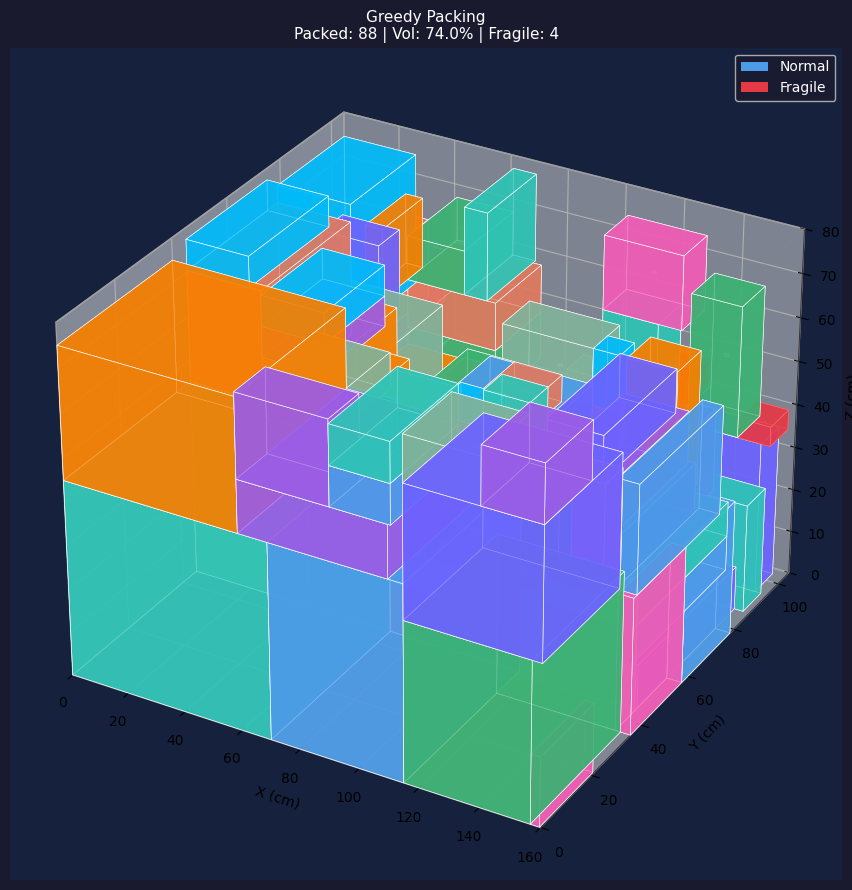

In [38]:
# ── Greedy — static 3D visualisation ─────────────────────────────────────────
visualize_packing(greedy_cont, g_packed,
                  title="Greedy Packing",
                  save_path=r"Statistics\greedy_packing.png")


In [39]:
# ── Greedy — interactive HTML visualisation ──────────────────────────────────
visualize_packing_html(greedy_cont, g_packed,
                       title="Greedy Packing",
                       save_path=r"Statistics\greedy_packing.html")


  Interactive HTML saved → C:\Users\TRETEC\Desktop\Yousra_BEDJGHIT_Project_10\Notebook\Statistics\greedy_packing.html


---
<a id='7'></a>
## 7. Algorithm 2 — Simulated Annealing (SA)

### Design

SA treats the **ordering of boxes** as the search space.  
A fixed placement heuristic (DBLF — Deepest-Bottom-Left-Fill) decodes any ordering  
into an actual 3D packing, and the objective function evaluates its quality.

| Component | Design choice |
|---|---|
| **State representation** | Permutation of box IDs |
| **Decoder** | DBLF: places each box at the lowest, most-left EP available |
| **Initial state** | Greedy heuristic sequence (non-fragile large→small, then fragile) |
| **Neighbour generation** | If boxes remain unplaced: move up to 3 failed boxes earlier; else: 3 random swaps |
| **Acceptance** | Metropolis criterion: always accept improvements; accept worse solutions with probability exp(Δf / T) |
| **Cooling schedule** | Geometric: T ← max(T × cooling_rate, T_end) |
| **Termination** | T drops below T_end |

The DBLF decoder generates and maintains **extreme points** (EPs) — candidate placement  
positions grown from the corners of already-placed boxes.  
A gravity projection step (`project_ep_down`) snaps each EP to the nearest solid surface  
below it, enforcing physically valid placements.

**Key parameters:** T_start=100, T_end=0.1, cooling=0.995 (≈920 iterations at default settings)


In [40]:
def place_box(box, position, rotation_index, container):
    if not can_place(box, position, rotation_index, container):
        box.rotation = None
        raise ValueError(
            f"Invalid placement: box '{box.id}' at {position} "
            f"with rotation {rotation_index}."
        )
    container.add_box(box, position=position, rotation=rotation_index)

def dblf_pack(box_sequence, container, alpha=0.6):
    for box in box_sequence:
        box.reset()
    extreme_points = [(0, 0, 0)]
    packed = []
    unpacked = []

    for box in box_sequence:
        sorted_eps = sorted(extreme_points, key=lambda p: (p[2], p[1], p[0]))
        placed = False

        for raw_ep in sorted_eps:
            ep = project_ep_down(raw_ep, container)
            if not can_fit_any_rotation(box, ep, container):
                continue
            for rot_idx in get_effective_rotations(box):
                if can_place(box, ep, rot_idx, container):
                    place_box(box, ep, rot_idx, container)
                    new_eps = generate_extreme_points(box, container)
                    extreme_points.extend(new_eps)
                    if raw_ep in extreme_points:
                        extreme_points.remove(raw_ep)
                    extreme_points = list(set(extreme_points))
                    if len(extreme_points) > 300:
                        extreme_points = sorted(extreme_points, key=lambda p: (p[2], p[1], p[0]))[:300]
                    packed.append(box)
                    placed = True
                    break
            if placed:
                break

        if not placed:
            unpacked.append(box)

    score = objective(container, alpha=alpha, unplaced_boxes=unpacked, total_boxes=len(box_sequence))
    return packed, unpacked, score


def generate_extreme_points(placed_box, container):
    dx, dy, dz = placed_box.get_rotation_dims()
    x0, y0, z0 = placed_box.position
    ep_right   = (x0 + dx, y0,      z0)
    ep_forward = (x0,      y0 + dy, z0)
    ep_top     = (x0,      y0,      z0 + dz)
    new_eps = []
    for ep in [ep_right, ep_forward, ep_top]:
        if _ep_inside_container(ep, container):
            new_eps.append(ep)
    return new_eps


def _ep_inside_container(ep, container):
    x, y, z = ep
    return (0 <= x < container.L and
            0 <= y < container.W and
            0 <= z < container.H)


def project_ep_down(ep, container):
    x, y, z_original = ep
    best_z = 0
    for box in container.boxes:
        bx, by, bz = box.position
        bdx, bdy, bdz = box.get_rotation_dims()
        if bx <= x < bx + bdx and by <= y < by + bdy:
            top_surface = bz + bdz
            if top_surface <= z_original:
                best_z = max(best_z, top_surface)
    return (x, y, best_z)


def filter_dominated_eps(eps, container):
    valid = [ep for ep in eps if _ep_inside_container(ep, container)]
    non_dominated = []
    for i, (xa, ya, za) in enumerate(valid):
        dominated = False
        for j, (xb, yb, zb) in enumerate(valid):
            if i == j:
                continue
            if xb <= xa and yb <= ya and zb <= za and (xb, yb, zb) != (xa, ya, za):
                dominated = True
                break
        if not dominated:
            non_dominated.append((xa, ya, za))
    return non_dominated


def _ep_is_occupied(ep, container):
    x, y, z = ep
    for box in container.boxes:
        bx, by, bz = box.position
        bdx, bdy, bdz = box.get_rotation_dims()
        if bx <= x < bx + bdx and by <= y < by + bdy and bz <= z < bz + bdz:
            return True
    return False


def score_rotation(box, position, rotation_index, container):
    allowed = get_allowed_rotations(box)
    if rotation_index not in allowed:
        return float('inf')
    all_rots = box.get_possible_rotations()
    dx, dy, dz = all_rots[rotation_index]
    x, y, z = position
    if x + dx > container.L or y + dy > container.W or z + dz > container.H:
        return float('inf')
    headroom = container.H - (z + dz)
    contact_area = dx * dy
    return headroom - 0.1 * contact_area


def can_fit_any_rotation(box, ep, container):
    x, y, z = ep
    all_rotations = box.get_possible_rotations()
    for dx, dy, dz in all_rotations:
        if (x + dx <= container.L and
            y + dy <= container.W and
            z + dz <= container.H):
            return True
    return False


def sa_neighbour(sequence, unpacked_boxes):
    import random
    new_seq = sequence[:]
    if not unpacked_boxes:
        for _ in range(3):
            i, j = random.sample(range(len(new_seq)), 2)
            new_seq[i], new_seq[j] = new_seq[j], new_seq[i]
        return new_seq
    unpacked_indices = [i for i, box in enumerate(new_seq) if box in unpacked_boxes]
    if unpacked_indices:
        n_to_move = min(len(unpacked_indices), 3)
        for failed_idx in random.sample(unpacked_indices, n_to_move):
            if failed_idx > 0:
                earlier_idx = random.randint(0, failed_idx - 1)
                new_seq[failed_idx], new_seq[earlier_idx] = new_seq[earlier_idx], new_seq[failed_idx]
            else:
                later_idx = random.randint(1, len(new_seq) - 1)
                new_seq[failed_idx], new_seq[later_idx] = new_seq[later_idx], new_seq[failed_idx]
    return new_seq


def simulated_annealing(boxes, container, alpha=0.6, T_start=100.0, T_end=0.1, cooling=0.995):
    current_seq = greedy_sequence(boxes)
    container.reset()
    packed, unpacked, current_score = dblf_pack(current_seq, container, alpha)
    best_seq = current_seq[:]
    best_score = current_score
    T = T_start

    while T > T_end:
        neighbour_seq = sa_neighbour(current_seq, unpacked)
        container.reset()
        n_packed, n_unpacked, neighbour_score = dblf_pack(neighbour_seq, container, alpha)
        delta = neighbour_score - current_score
        if delta > 0 or random.random() < math.exp(delta / T):
            current_seq   = neighbour_seq
            current_score = neighbour_score
            unpacked      = n_unpacked
        if current_score > best_score:
            best_seq   = current_seq[:]
            best_score = current_score
        T = max(T * cooling, T_end)

    container.reset()
    packed, unpacked, score = dblf_pack(best_seq, container, alpha)
    return best_seq, packed, unpacked, score


def greedy_sequence(boxes):
    BIG_FRAGILE_THRESHOLD = 20000
    big_fragile  = sorted([b for b in boxes if b.fragile == 1 and b.volume >= BIG_FRAGILE_THRESHOLD], key=lambda b: b.volume, reverse=True)
    non_fragile  = sorted([b for b in boxes if b.fragile == 0], key=lambda b: b.volume, reverse=True)
    small_fragile= sorted([b for b in boxes if b.fragile == 1 and b.volume < BIG_FRAGILE_THRESHOLD],  key=lambda b: b.volume, reverse=True)
    return non_fragile + big_fragile + small_fragile


import csv

def load_boxes_from_csv(filepath='/content/dataset.csv'):
    boxes_list = []

    def _safe_float(value, default=0.0):
        try:
            return float(str(value).strip())
        except (ValueError, AttributeError):
            return default

    def _safe_int(value, default=0):
        try:
            return int(str(value).strip())
        except (ValueError, AttributeError):
            return default

    with open(filepath, mode='r', encoding='utf-8') as file:
        reader = csv.DictReader(file)
        for row in reader:
            if not any(str(v).strip() for v in row.values() if v is not None):
                continue
            box = Box(
                box_id =_safe_int  (row.get('ID',           0)),
                length =_safe_float(row.get('Length_cm',    0)),
                width  =_safe_float(row.get('Width_cm',     0)),
                height =_safe_float(row.get('Height_cm',    0)),
                weight =_safe_float(row.get('Weight_kg',    0)),
                fragile=_safe_int  (row.get('fragile_flag', 0)),
            )
            boxes_list.append(box)
    return boxes_list



# ── Run Simulated Annealing ───────────────────────────────────────────────────
import copy, time, math, random

random.seed(42)

sa_boxes   = [copy.deepcopy(b) for b in ALL_BOXES]
sa_cont    = Container(**CONTAINER_DIMS)

print("--- Running Simulated Annealing ---")
t0 = time.time()
best_seq, sa_packed, sa_unpacked, sa_score = simulated_annealing(
    boxes     = sa_boxes,
    container = sa_cont,
    alpha     = 0.9,
    T_start   = 100.0,
    T_end     = 0.1,
    cooling   = 0.98,
)
sa_time = time.time() - t0

print(f"\n{'='*55}")
print(f"  SIMULATED ANNEALING RESULTS")
print(f"{'='*55}")
print(f"  Boxes packed    : {len(sa_packed)} / {len(sa_boxes)}")
print(f"  Boxes unpacked  : {len(sa_unpacked)}")
print(f"  Volume util.    : {volume_utilization(sa_cont):.2f}%")
print(f"  Stability score : {stability_score(sa_cont):.4f}")
print(f"  Objective score : {sa_score:.4f}")
print(f"  Runtime         : {sa_time:.2f} s")
print(f"{'='*55}")


--- Running Simulated Annealing ---

  SIMULATED ANNEALING RESULTS
  Boxes packed    : 102 / 109
  Boxes unpacked  : 7
  Volume util.    : 79.99%
  Stability score : 0.5798
  Objective score : 77.3990
  Runtime         : 283.04 s


  Saved → Statistics\sa_packing.png


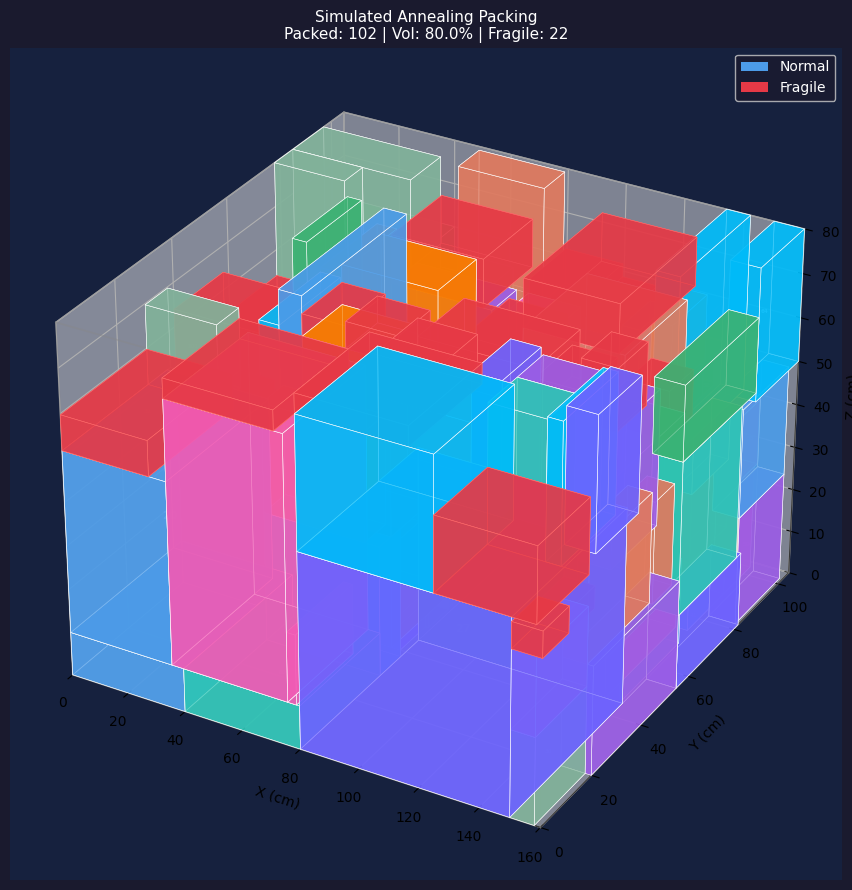

In [41]:
# ── SA — static 3D visualisation ─────────────────────────────────────────────
visualize_packing(sa_cont, sa_packed,
                  title="Simulated Annealing Packing",
                  save_path=r"Statistics\sa_packing.png")


In [ ]:
# ── SA — interactive HTML visualisation ──────────────────────────────────────
visualize_packing_html(sa_cont, sa_packed,
                       title="Simulated Annealing — Best Solution",
                       save_path=r"Statistics\sa_packing.html")


---
<a id='8'></a>
## 8. Algorithm 3 — Genetic Algorithm (GA)

### Design

The GA maintains a **population of box orderings** (permutations).  
The same DBLF decoder translates each individual into a packing.

| Component | Design choice |
|---|---|
| **Individual** | Permutation of box IDs |
| **Population size** | 100 individuals |
| **Initialisation** | 30% biased (12 heuristic seeding strategies) + 70% random |
| **Fitness** | `objective()` shared with SA and Greedy |
| **Selection** | Tournament selection (size 3) |
| **Crossover** | 50% Uniform Order Crossover (UOX) · 50% Order Crossover (OX) |
| **Mutation** | 50% swap · 25% reverse segment · 25% displace segment |
| **Elitism** | Top 10% survive without modification |
| **Random injection** | 10% fresh individuals each generation (diversity maintenance) |
| **Stagnation handling** | Mutation rate ×2 + perturbation after 30 idle generations |
| **Early stopping** | Patience = 50 generations without improvement |
| **Parallelism** | Multi-process fitness evaluation via `multiprocessing.Pool` |

**Decoder note:** The GA uses its own `Decoder` class which is a streamlined DBLF  
variant that stores placements as raw tuples (avoiding shared-state issues across processes).


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
#  ALGORITHM 3 — GENETIC ALGORITHM
# ═══════════════════════════════════════════════════════════════════════════

import csv
from collections import Counter
from multiprocessing import Pool, cpu_count


# ── GA Decoder (process-safe DBLF variant) ────────────────────────────────────

class Decoder:
    """
    Compact DBLF decoder used by the GA.
    Stores placements as (x,y,z,dx,dy,dz,is_fragile) tuples to avoid
    shared Box-object state across worker processes.
    """

    def __init__(self, container):
        self.cl, self.cw, self.ch = (round(float(container.L), 1),
                                      round(float(container.W), 1),
                                      round(float(container.H), 1))
        self.max_weight   = container.max_weight
        self.weight       = 0.0
        self.placed_boxes = []
        self.eps          = [(0.0, 0.0, 0.0)]

    def _check_constraints(self, bx, by, bz, bdx, bdy, bdz, weight, is_fragile):
        # 1. Boundary
        bx2, by2, bz2 = bx+bdx, by+bdy, bz+bdz
        if bx2 > self.cl or by2 > self.cw or bz2 > self.ch:
            return False
        supported_area = 0.0
        for ox, oy, oz, odx, ody, odz, o_fragile in self.placed_boxes:
            # 2. Overlap
            if not (bx2 <= ox or bx >= ox+odx or
                    by2 <= oy or by >= oy+ody or
                    bz2 <= oz or bz >= oz+odz):
                return False
            # 3. Gravity support  +  4. Fragility
            if abs((oz+odz) - bz) < 0.1:
                ix = min(bx2, ox+odx) - max(bx, ox)
                iy = min(by2, oy+ody) - max(by, oy)
                if ix > 0 and iy > 0:
                    if o_fragile:
                        return False
                    supported_area += ix * iy
            if is_fragile and abs(round(bz+bdz,1) - oz) < 0.1:
                ix = min(bx2, ox+odx) - max(bx, ox)
                iy = min(by2, oy+ody) - max(by, oy)
                if ix > 0 and iy > 0:
                    return False
        if bz > 0.01 and (supported_area / (bdx*bdy)) < 0.70:
            return False
        # 5. Weight
        if self.weight + weight > self.max_weight:
            return False
        return True

    def _update_eps(self, bx, by, bz, bdx, bdy, bdz):
        bx2, by2, bz2 = round(bx+bdx,1), round(by+bdy,1), round(bz+bdz,1)
        for p in [(bx2,by,bz),(bx,by2,bz),(bx,by,bz2)]:
            if p[0] < self.cl and p[1] < self.cw and p[2] < self.ch:
                self.eps.append(p)
        self.eps = [p for p in self.eps
                    if not (bx <= p[0] < bx2 and by <= p[1] < by2 and bz <= p[2] < bz2)]
        self.eps.sort(key=lambda p: (p[2], p[1], p[0]))

    def pack(self, box_id, boxes_dict):
        box       = boxes_dict[box_id]
        is_frag   = bool(box.fragile)
        eff_rots  = get_effective_rotations(box)
        rotations = box.get_possible_rotations()
        weight    = box.weight

        best_pos, best_rot = None, None
        min_score = (float('inf'),) * 3
        EPs = list(reversed(self.eps)) if is_frag else self.eps

        for r_idx in eff_rots:
            bdx, bdy, bdz = rotations[r_idx]
            for px, py, pz in EPs:
                if self._check_constraints(px, py, pz, bdx, bdy, bdz, weight, is_frag):
                    score = (-pz, py, px) if is_frag else (pz, py, px)
                    if score < min_score:
                        min_score = score
                        best_pos  = (round(px,1), round(py,1), round(pz,1))
                        best_rot  = r_idx
                    break   # EPs are sorted; first fit for this rotation is best candidate

        if best_pos:
            bx, by, bz = best_pos
            bdx, bdy, bdz = rotations[best_rot]
            self.weight += weight
            self.placed_boxes.append((round(bx,1), round(by,1), round(bz,1),
                                      round(bdx,1), round(bdy,1), round(bdz,1), is_frag))
            self._update_eps(bx, by, bz, bdx, bdy, bdz)
            return best_pos, best_rot
        return None, None


def decoder(individual, container, boxes_dict):
    """Decode an ordering into a packing using the GA Decoder."""
    container.reset()
    for b_id in individual:
        boxes_dict[b_id].reset()
    engine  = Decoder(container)
    unplaced = []
    for box_id in individual:
        pos, rot = engine.pack(box_id, boxes_dict)
        if pos:
            container.add_box(boxes_dict[box_id], position=pos, rotation=rot)
        else:
            unplaced.append(box_id)
    return container, unplaced


# ── Parallel evaluation ───────────────────────────────────────────────────────
_w_container = _w_boxes_dict = _w_alpha = _w_penalty = None

def _worker_init(container, boxes_dict, alpha, penalty):
    global _w_container, _w_boxes_dict, _w_alpha, _w_penalty
    _w_container  = container
    _w_boxes_dict = boxes_dict
    _w_alpha      = alpha
    _w_penalty    = penalty

def _worker_evaluate(individual):
    res_container, unplaced_ids = decoder(individual, _w_container, _w_boxes_dict)
    unplaced_boxes = [_w_boxes_dict[b_id] for b_id in unplaced_ids]
    return objective(res_container, _w_alpha, unplaced_boxes, len(_w_boxes_dict), _w_penalty)


# ── Crossover operators ───────────────────────────────────────────────────────

def uniform_order_crossover(p1, p2):
    """UOX: inherit 60% of positions from p1, fill gaps in p2's order."""
    size = len(p1);  child = [None]*size
    for i in range(size):
        if random.random() < 0.6:
            child[i] = p1[i]
    in_child = {c for c in child if c is not None}
    fill = [x for x in p2 if x not in in_child]
    idx = 0
    for i in range(size):
        if child[i] is None:
            child[i] = fill[idx];  idx += 1
    return child


def ox_crossover(p1, p2):
    """OX: copy a contiguous slice from p1, fill the rest in p2's order."""
    size = len(p1);  a, b = sorted(random.sample(range(size), 2))
    child = [None]*size;  child[a:b+1] = p1[a:b+1]
    in_child = set(child[a:b+1])
    fill = [x for x in p2 if x not in in_child]
    idx = 0
    for i in range(size):
        if child[i] is None:
            child[i] = fill[idx];  idx += 1
    return child


def crossover(p1, p2):
    return uniform_order_crossover(p1, p2) if random.random() < 0.5 else ox_crossover(p1, p2)


# ── Mutation operators ────────────────────────────────────────────────────────

def swap_mutation(ind):
    res = ind[:];  a, b = random.sample(range(len(res)), 2)
    res[a], res[b] = res[b], res[a];  return res

def reverse_mutation(ind):
    res = ind[:];  a, b = sorted(random.sample(range(len(res)), 2))
    res[a:b+1] = res[a:b+1][::-1];  return res

def displace_mutation(ind):
    res = ind[:];  a, b = sorted(random.sample(range(len(res)), 2))
    seg = res[a:b+1];  del res[a:b+1]
    at  = random.randint(0, len(res));  res[at:at] = seg;  return res

def mutate(ind):
    r = random.random()
    if r < 0.50: return swap_mutation(ind)
    if r < 0.75: return reverse_mutation(ind)
    return displace_mutation(ind)


# ── Individual creation ───────────────────────────────────────────────────────

def create_individual(box_ids, boxes_dict, initial=False):
    """30% (initial) or 15% (ongoing) chance of a seeded heuristic ordering."""
    n = len(box_ids)
    if random.random() < (0.30 if initial else 0.15):
        r = random.randint(0, 12)
        B = boxes_dict
        if r == 0:  return sorted(box_ids, key=lambda b: B[b].volume,   reverse=True)
        if r == 1:  return sorted(box_ids, key=lambda b: max(B[b].L,B[b].W,B[b].H), reverse=True)
        if r == 2:  return sorted(box_ids, key=lambda b: B[b].weight,   reverse=True)
        if r == 3:  return sorted(box_ids, key=lambda b: B[b].L,        reverse=True)
        if r == 4:  return sorted(box_ids, key=lambda b: B[b].W,        reverse=True)
        if r == 5:  return sorted(box_ids, key=lambda b: B[b].H,        reverse=True)
        if r == 6:  return sorted(box_ids, key=lambda b: B[b].fragile,  reverse=True)
        if r == 7:
            nf = sorted([b for b in box_ids if B[b].fragile==0], key=lambda b: B[b].weight, reverse=True)
            fr = sorted([b for b in box_ids if B[b].fragile==1], key=lambda b: B[b].weight)
            return nf + fr
        if r == 8:
            nf = sorted([b for b in box_ids if B[b].fragile==0], key=lambda b: B[b].volume, reverse=True)
            fr = sorted([b for b in box_ids if B[b].fragile==1], key=lambda b: B[b].volume, reverse=True)
            return nf + fr
        if r == 9:  return sorted(box_ids, key=lambda b: B[b].weight/B[b].volume, reverse=True)
        if r == 10: return sorted(box_ids, key=lambda b: B[b].base_area(), reverse=True)
        if r == 11:
            nf = sorted([b for b in box_ids if B[b].fragile==0], key=lambda b: B[b].base_area(), reverse=True)
            fr = sorted([b for b in box_ids if B[b].fragile==1], key=lambda b: B[b].base_area(), reverse=True)
            return nf + fr
        return sorted(box_ids, key=lambda b: (B[b].volume, B[b].weight), reverse=True)
    return random.sample(box_ids, n)


# ── Perturbation (diversity recovery) ────────────────────────────────────────

def perturbate_population(population, box_ids, elite_ind, n_elites, mutation_rate):
    n = len(population);  size = len(box_ids)
    new_pop = list(population[:n_elites])
    mid = n // 2
    for ind in population[n_elites:mid]:
        p = ind[:]
        for _ in range(random.randint(2, 4)):
            a = random.randint(0, size-2)
            b = random.randint(a+1, min(a + max(1, size//4), size))
            seg = p[a:b];  random.shuffle(seg);  p[a:b] = seg
        new_pop.append(p)
    for _ in range(n - mid):
        if random.random() < 0.5:
            new_pop.append(random.sample(box_ids, size))
        else:
            base = random.choice(population[n_elites:])[:]
            a, b = sorted(random.sample(range(size), 2))
            seg = base[a:b+1];  del base[a:b+1]
            at  = random.randint(0, len(base));  base[at:at] = seg
            new_pop.append(base)
    return new_pop


def tournament_select(ranked_population, tournament_size=3):
    idxs = random.sample(range(len(ranked_population)), min(tournament_size, len(ranked_population)))
    return ranked_population[min(idxs)]


# ── Main GA function ──────────────────────────────────────────────────────────

def genetic_algorithm(boxes_dict, container,
                      pop_size=100, generations=100,
                      elite_prop=0.1, random_injection_prop=0.1,
                      patience=50, min_delta=0.1,
                      alpha=0.6, unplaced_penalty=0.15,
                      mutation_rate=0.1, max_time = 180,
                      verbose=True):
    """
    GA over box orderings, decoded via GA Decoder (DBLF variant).
    Returns best_individual, best_fitness, fitness_history.
    """
    box_ids     = list(boxes_dict.keys())
    num_workers = max(1, cpu_count())

    population = [create_individual(box_ids, boxes_dict, True) for _ in range(pop_size)]

    best_ever_fit = -float('inf');  best_ever_ind = None
    no_improve    = 0;              history        = []
    start_t       = time.time()

    with Pool(processes=num_workers, initializer=_worker_init,
              initargs=(container, boxes_dict, alpha, unplaced_penalty)) as pool:

        for gen in range(generations):
            elapsed_time = int(time.time() - start_t)
            fits   = pool.map(_worker_evaluate, population)
            ranked = sorted(zip(population, fits), key=lambda x: x[1], reverse=True)
            cur_best_ind, cur_best_fit = ranked[0]

            if cur_best_fit - best_ever_fit >= min_delta:
                best_ever_fit = cur_best_fit
                best_ever_ind = cur_best_ind[:]
                no_improve    = 0
            else:
                no_improve += 1
            history.append(best_ever_fit)

            if verbose:
                rc, _ = decoder(best_ever_ind, container, boxes_dict)
                print(f"Gen {gen:3d} | Fit: {best_ever_fit:.4f} | "
                      f"Util: {volume_utilization(rc):.2f}% | "
                      f"Stall: {no_improve}/{patience} | "
                      f"{elapsed_time}s")

            if no_improve >= patience or elapsed_time >= max_time:
                if verbose:
                    print(f"Early stop: no improvement for {patience} generations or maximum elapsed time")
                break

            n_elites   = max(4, int(pop_size * elite_prop))
            n_injected = int(pop_size * random_injection_prop)
            mr         = mutation_rate

            if no_improve >= int(patience * 0.33):
                mr         = mutation_rate * 2
                n_elites   = max(2, int(n_elites * 0.5))
                n_injected = n_injected + n_elites

            elites  = [ind for ind, _ in ranked[:n_elites]]
            new_pop = list(elites)
            for _ in range(n_injected):
                new_pop.append(create_individual(box_ids, boxes_dict, False))

            all_inds = [ind for ind, _ in ranked]
            while len(new_pop) < pop_size:
                p1    = (random.choice(elites) if random.random() < 0.33
                         else tournament_select(all_inds))
                p2    = (random.choice(population) if random.random() < 0.33
                         else tournament_select(all_inds))
                child = crossover(p1, p2)
                if random.random() < mr:
                    child = mutate(child)
                new_pop.append(child)

            population = new_pop
            if no_improve > 30 and no_improve % 20 == 0:
                population = perturbate_population(population, box_ids, best_ever_ind, n_elites, mr)

    return best_ever_ind, best_ever_fit, history


print("✔  Genetic Algorithm defined.")


In [ ]:
# ── Helper: build boxes_dict from list ────────────────────────────────────────

def build_boxes_dict(boxes):
    """Build the {id: Box} dictionary the GA expects from a list of Box objects."""
    name_counts = Counter()
    result = {}
    for box in boxes:
        bid = str(box.id)
        name_counts[bid] += 1
        if name_counts[bid] > 1:
            bid = f"{bid}_{name_counts[bid]}"
        result[bid] = box
    return result


In [ ]:
# ── Run Genetic Algorithm ─────────────────────────────────────────────────────
random.seed(42)

ga_boxes      = [copy.deepcopy(b) for b in ALL_BOXES]
ga_cont       = Container(**CONTAINER_DIMS)
ga_boxes_dict = build_boxes_dict(ga_boxes)

t0 = time.time()
ga_best_ind, ga_best_fit, ga_history = genetic_algorithm(
    boxes_dict          = ga_boxes_dict,
    container           = ga_cont,
    pop_size            = 100,
    generations         = 100,
    elite_prop          = 0.10,
    random_injection_prop=0.10,
    patience            = 50,
    min_delta           = 0.1,
    alpha               = 0.6,
    unplaced_penalty    = 0.5,
    mutation_rate       = 0.10,
    verbose             = True,
)
ga_time = time.time() - t0

# Decode best individual into final packing
ga_cont_final, ga_unplaced_ids = decoder(ga_best_ind, ga_cont, ga_boxes_dict)
ga_packed   = [b for b in ga_boxes_dict.values() if b.placed]
ga_unpacked = [ga_boxes_dict[b_id] for b_id in ga_unplaced_ids]

print(f"\n{'='*55}")
print(f"  GENETIC ALGORITHM RESULTS")
print(f"{'='*55}")
print(f"  Boxes packed    : {len(ga_packed)} / {len(ga_boxes_dict)}")
print(f"  Boxes unpacked  : {len(ga_unpacked)}")
print(f"  Volume util.    : {volume_utilization(ga_cont_final):.2f}%")
print(f"  Stability score : {stability_score(ga_cont_final):.4f}")
print(f"  Objective score : {ga_best_fit:.4f}")
print(f"  Runtime         : {ga_time:.2f} s")
print(f"{'='*55}")


In [ ]:
# ── GA — convergence curve ────────────────────────────────────────────────────
plt.figure(figsize=(10, 5))
plt.plot(ga_history, color='#6C63FF', linewidth=2, label='Best Fitness')
plt.fill_between(range(len(ga_history)), ga_history, alpha=0.15, color='#6C63FF')
plt.xlabel("Generation", fontsize=12)
plt.ylabel("Objective Score", fontsize=12)
plt.title("GA Convergence Curve", fontsize=13, fontweight='bold')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(r"Statistics\ga_convergence.png", dpi=120, bbox_inches='tight')
plt.show()



In [ ]:
# ── GA — static 3D visualisation ─────────────────────────────────────────────
visualize_packing(ga_cont_final, ga_packed,
                  title="Genetic Algorithm Packing",
                  save_path=r"Statistics\ga_packing.png")


In [ ]:
# ── GA — interactive HTML visualisation ──────────────────────────────────────
visualize_packing_html(ga_cont_final, ga_packed,
                       title="Genetic Algorithm — Best Solution",
                       save_path=r"Statistics\ga_packing.html")


---
<a id='9'></a>
## 9. Results & Comparative Analysis


In [ ]:
total_boxes = len(ALL_BOXES)

results = {
    "Algorithm"       : ["Greedy", "Simulated Annealing", "Genetic Algorithm"],
    "Packed"          : [len(g_packed), len(sa_packed), len(ga_packed)],
    "Unpacked"        : [len(g_unpacked), len(sa_unpacked), len(ga_unpacked)],
    "Volume Util. (%)":[round(volume_utilization(greedy_cont), 2),
                        round(volume_utilization(sa_cont), 2),
                        round(volume_utilization(ga_cont_final), 2)],
    "Stability Score" :[round(stability_score(greedy_cont), 4),
                        round(stability_score(sa_cont), 4),
                        round(stability_score(ga_cont_final), 4)],
    "Objective Score" :[round(g_score, 4), round(sa_score, 4), round(ga_best_fit, 4)],
    "Runtime (s)"     :[round(greedy_time, 2), round(sa_time, 2), round(ga_time, 2)],
}

df_results = pd.DataFrame(results)
print("=== Comparative Results ===")
print(df_results.to_string(index=False))

In [ ]:
# ── Bar chart comparison ──────────────────────────────────────────────────────
metrics = ['Volume Util. (%)', 'Stability Score', 'Objective Score']
colors  = ['#4C9BE8', '#F77F00', '#6C63FF']
algos   = df_results["Algorithm"].tolist()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Algorithm Comparison — 109-Box Dataset", fontsize=14, fontweight='bold')

for ax, metric, color in zip(axes, metrics, colors):
    vals = df_results[metric].tolist()
    bars = ax.bar(algos, vals, color=color, edgecolor='white', linewidth=0.8)
    ax.set_title(metric, fontweight='bold')
    ax.set_ylabel(metric)
    ax.set_ylim(0, max(vals) * 1.15)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(vals)*0.02,
                f"{v:.2f}", ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    ax.set_xticklabels(algos, rotation=15, ha='right')

plt.tight_layout()
plt.savefig(r"Statistics\algorithm_comparison.png", dpi=130, bbox_inches='tight')
plt.show()



In [ ]:
# ── Packed vs Unpacked stacked bar ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))
x = range(len(algos))
ax.bar(x, df_results["Packed"],   label="Packed",   color='#3BB273', edgecolor='white')
ax.bar(x, df_results["Unpacked"], bottom=df_results["Packed"],
       label="Unpacked", color='#E63946', edgecolor='white')

for i, (p, u) in enumerate(zip(df_results["Packed"], df_results["Unpacked"])):
    ax.text(i, p/2,   str(p), ha='center', va='center', color='white', fontweight='bold')
    if u > 0:
        ax.text(i, p+u/2, str(u), ha='center', va='center', color='white', fontweight='bold')

ax.set_xticks(list(x)); ax.set_xticklabels(algos)
ax.set_ylabel("Number of Boxes"); ax.set_title("Packed vs Unpacked Boxes", fontweight='bold')
ax.axhline(total_boxes, linestyle='--', color='gray', linewidth=1, label=f"Total ({total_boxes})")
ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(r"Statistics\packed_vs_unpacked.png", dpi=130, bbox_inches='tight')
plt.show()


In [ ]:
# ── Runtime comparison ────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(algos, df_results["Runtime (s)"], color=['#4C9BE8','#F77F00','#6C63FF'],
              edgecolor='white')
ax.set_ylabel("Runtime (seconds)"); ax.set_title("Runtimes", fontweight='bold')
for bar, v in zip(bars, df_results["Runtime (s)"]):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f"{v:.1f}s", ha='center', fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(r"Statistics\runtimes.png", dpi=130, bbox_inches='tight')
plt.show()


---
<a id='10'></a>
## 10. Conclusion

This notebook compared three AI search approaches to the 3D Bin Packing Problem  
using a 109-box dataset collected from real Algerian delivery companies.

### Key findings

| Aspect | Observation |
|---|---|
| **Space efficiency** | SA and GA improve over the greedy baseline through iterative refinement |
| **Solution quality** | GA explores a larger solution space but requires significantly more computation |
| **Speed** | Greedy is the fastest; GA is the slowest due to population evaluation (it really depends on the initial parameters) |
| **Stability** | All three approaches produce physically stable packings (score ≥ 0.55) |
| **Fragility** | The shared constraint model correctly prevents fragile boxes from being loaded under other boxes |

### Practical takeaways

- The **greedy algorithm** is best for real-time operational use where a solution is needed in under 1 second.  
- **Simulated annealing** offers the best trade-off between quality and speed for medium batch sizes.  
- The **genetic algorithm** is best suited for offline optimisation where compute time is available and  
  maximum packing density is the priority.

### Limitations & future work
- The dataset is synthetic; production deployment would benefit from larger, validated datasets.  
- Incorporating real weight constraints and multiple container types would improve practical applicability.  
- Hybrid approaches (GA seeded with greedy output, SA warm-started from GA best) could further improve results.
